In [14]:
import os, json, math, time, random
from pathlib import Path
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

DATA_DIR = "."          # shakespeare_train.txt / shakespeare_valid.txt 所在資料夾
OUT_DIR  = "outputs"    # 模型、history、圖片都存這裡 (三個 notebook 共用)
os.makedirs(OUT_DIR, exist_ok=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available(): device = torch.device("cuda")
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available(): device = torch.device("mps")
else: device = torch.device("cpu")
print("device:", device)

device: cuda


In [15]:
TOKENIZER = "char"      # "char" 或 "bpe"
BPE_VOCAB = 1000
BLOCK_SIZE, BATCH_SIZE = 128, 64
EPOCHS = 20
PROMPT = "ROMEO:"       # breakpoint 生成用的 seed

# --- 2-1 LSTM 架構 (報告要寫) ---
LSTM_CFG = dict(emb_dim=256, hidden_dim=512, num_layers=2, dropout=0.3)
LSTM_LR = 2e-3

# --- 2-2 Transformer 架構 (報告要寫) ---
GPT_CFG = dict(n_embd=256, n_head=4, n_layer=4, ff_dim=1024, dropout=0.2)
GPT_LR = 1e-3

In [16]:
class CharTokenizer:
    def __init__(self, chars):
        self.chars = list(chars)
        self.stoi = {c: i for i, c in enumerate(self.chars)}
        self.itos = {i: c for c, i in self.stoi.items()}
    @classmethod
    def from_text(cls, text): return cls(sorted(set(text)))
    @property
    def vocab_size(self): return len(self.chars)
    def encode(self, text): return [self.stoi[c] for c in text if c in self.stoi]
    def decode(self, ids): return "".join(self.itos[int(i)] for i in ids)
    def to_dict(self): return {"type": "char", "chars": self.chars}

class BPETokenizer:
    def __init__(self, tk): self.tk = tk
    @classmethod
    def train(cls, text, vocab_size=1000):
        from tokenizers import Tokenizer, models, pre_tokenizers, decoders, trainers
        tk = Tokenizer(models.BPE())
        tk.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
        tk.decoder = decoders.ByteLevel()
        trainer = trainers.BpeTrainer(vocab_size=vocab_size, show_progress=False,
                                      initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
        tk.train_from_iterator(text.splitlines(keepends=True), trainer)
        return cls(tk)
    @property
    def vocab_size(self): return self.tk.get_vocab_size()
    def encode(self, text): return self.tk.encode(text).ids
    def decode(self, ids): return self.tk.decode([int(i) for i in ids])
    def to_dict(self): return {"type": "bpe", "json": self.tk.to_str()}

def tokenizer_from_dict(d):
    if d["type"] == "char": return CharTokenizer(d["chars"])
    from tokenizers import Tokenizer
    return BPETokenizer(Tokenizer.from_str(d["json"]))

def build_tokenizer(kind, train_text, valid_text, bpe_vocab=1000):
    if kind == "char":   # 用 train+valid 建字表，避免 valid 出現沒見過的字元
        return CharTokenizer.from_text(train_text + valid_text)
    return BPETokenizer.train(train_text, bpe_vocab)

In [17]:
def to_chunks(ids, block_size):
    # 把長序列切成不重疊片段；y 是 x 往右位移一格 → 每個位置都在預測「下一個 token」
    ids = torch.tensor(ids, dtype=torch.long)
    n = (len(ids) - 1) // block_size
    x = ids[: n * block_size].view(n, block_size)
    y = ids[1 : n * block_size + 1].view(n, block_size)
    return TensorDataset(x, y)

def make_loaders(tok, train_text, valid_text, block_size, batch_size):
    tr = to_chunks(tok.encode(train_text), block_size)
    va = to_chunks(tok.encode(valid_text), block_size)
    return (DataLoader(tr, batch_size=batch_size, shuffle=True, drop_last=True),
            DataLoader(va, batch_size=batch_size, shuffle=False))

In [18]:
train_text = Path(DATA_DIR, "shakespeare_train.txt").read_text(encoding="utf-8")
valid_text = Path(DATA_DIR, "shakespeare_valid.txt").read_text(encoding="utf-8")
tok = build_tokenizer(TOKENIZER, train_text, valid_text, BPE_VOCAB)
train_loader, val_loader = make_loaders(tok, train_text, valid_text, BLOCK_SIZE, BATCH_SIZE)
print(f"tokenizer={TOKENIZER}  vocab={tok.vocab_size}  train batches/epoch={len(train_loader)}  val batches={len(val_loader)}")

tokenizer=char  vocab=67  train batches/epoch=531  val batches=28


In [19]:
def sample_next(logits, temperature=1.0):
    # P(i) = exp(z_i / T) / sum_j exp(z_j / T)
    probs = F.softmax(logits / max(temperature, 1e-6), dim=-1)
    return torch.multinomial(probs, num_samples=1)

In [20]:
class LSTMLM(nn.Module):
    kind = "lstm"
    def __init__(self, vocab_size, emb_dim=256, hidden_dim=512, num_layers=2, dropout=0.3):
        super().__init__()
        self.config = dict(vocab_size=vocab_size, emb_dim=emb_dim, hidden_dim=hidden_dim,
                           num_layers=num_layers, dropout=dropout)
        self.emb = nn.Embedding(vocab_size, emb_dim)
        self.drop = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb_dim, hidden_dim, num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x, h=None, return_h=False):
        out, h = self.lstm(self.drop(self.emb(x)), h)
        logits = self.fc(self.drop(out))
        return (logits, h) if return_h else logits

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0):
        self.eval()
        logits, h = self(idx, return_h=True)          # 先讀完 prompt
        for _ in range(max_new_tokens):
            nxt = sample_next(logits[:, -1], temperature)
            idx = torch.cat([idx, nxt], dim=1)
            logits, h = self(nxt, h, return_h=True)   # 之後只餵新 token，沿用 hidden state
        return idx

In [21]:
class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        assert n_embd % n_head == 0
        self.n_head, self.dropout = n_head, dropout
        self.qkv = nn.Linear(n_embd, 3 * n_embd)
        self.proj = nn.Linear(n_embd, n_embd)
        self.attn_drop = nn.Dropout(dropout)
        self.res_drop = nn.Dropout(dropout)
        # causal mask：下三角為 True → 位置 t 只能看見 <= t
        mask = torch.tril(torch.ones(block_size, block_size, dtype=torch.bool))
        self.register_buffer("mask", mask.view(1, 1, block_size, block_size), persistent=False)
        self.store, self.last_attn = False, None      # store=True 時保存 attention (給 Q3 用)

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        if self.store:                                 # 手動算，才拿得到 attention weights
            att = (q @ k.transpose(-2, -1)) / math.sqrt(k.size(-1))
            att = att.masked_fill(~self.mask[:, :, :T, :T], float("-inf"))
            att = F.softmax(att, dim=-1)
            self.last_attn = att.detach()
            y = self.attn_drop(att) @ v
        else:                                          # 訓練用 fused kernel，is_causal=True 等價於上面的 mask
            y = F.scaled_dot_product_attention(q, k, v, is_causal=True,
                                               dropout_p=self.dropout if self.training else 0.0)
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.res_drop(self.proj(y))

class Block(nn.Module):
    def __init__(self, n_embd, n_head, ff_dim, block_size, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention(n_embd, n_head, block_size, dropout)
        self.ln2 = nn.LayerNorm(n_embd)
        self.mlp = nn.Sequential(nn.Linear(n_embd, ff_dim), nn.GELU(),
                                 nn.Linear(ff_dim, n_embd), nn.Dropout(dropout))
    def forward(self, x):
        x = x + self.attn(self.ln1(x))   # pre-LN + residual
        return x + self.mlp(self.ln2(x))

class MiniGPT(nn.Module):
    kind = "transformer"
    def __init__(self, vocab_size, block_size=128, n_embd=256, n_head=4, n_layer=4, ff_dim=1024, dropout=0.2):
        super().__init__()
        self.config = dict(vocab_size=vocab_size, block_size=block_size, n_embd=n_embd,
                           n_head=n_head, n_layer=n_layer, ff_dim=ff_dim, dropout=dropout)
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, n_embd)
        self.pos_emb = nn.Embedding(block_size, n_embd)       # learned positional encoding
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([Block(n_embd, n_head, ff_dim, block_size, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size)
        self.apply(self._init)

    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, 0.0, 0.02)
            if isinstance(m, nn.Linear) and m.bias is not None: nn.init.zeros_(m.bias)

    def forward(self, idx):
        B, T = idx.shape
        x = self.drop(self.tok_emb(idx) + self.pos_emb(torch.arange(T, device=idx.device)))
        for blk in self.blocks: x = blk(x)
        return self.head(self.ln_f(x))

    @torch.no_grad()
    def get_last_layer_attention(self, idx):
        self.eval()
        attn = self.blocks[-1].attn
        attn.store = True; self(idx); attn.store = False
        return attn.last_attn[0].cpu()                         # (n_head, T, T)

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0):
        self.eval()
        for _ in range(max_new_tokens):
            ctx = idx[:, -self.block_size:]                    # 只看最後 block_size 個 token
            nxt = sample_next(self(ctx)[:, -1], temperature)
            idx = torch.cat([idx, nxt], dim=1)
        return idx

In [22]:
def count_params(model): return sum(p.numel() for p in model.parameters())

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); tot, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        tot += F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1), reduction="sum").item()
        n += y.numel()
    return tot / n

def pick_epochs(epochs):   # 約 5%, 15%, 30%, 60%, 100% 的進度 → 5 個 breakpoint
    return sorted({max(1, round(epochs * f)) for f in (0.05, 0.15, 0.3, 0.6, 1.0)})

def fit(model, train_loader, val_loader, tok, *, name, epochs, lr, prompt="ROMEO:",
        sample_len=300, weight_decay=0.01, grad_clip=1.0, warmup_steps=100):
    model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    total_steps = epochs * len(train_loader)
    def lr_lambda(step):   # linear warm-up + cosine decay (最低 10%)
        if step < warmup_steps: return (step + 1) / warmup_steps
        p = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * p))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
    sample_epochs = set(pick_epochs(epochs))
    history, samples = [], []
    print(f"[{name}] params={count_params(model):,}  steps/epoch={len(train_loader)}  breakpoints={sorted(sample_epochs)}")

    for ep in range(1, epochs + 1):
        model.train()
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.time(); tot, n = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            opt.step(); sched.step()
            tot += loss.item() * y.numel(); n += y.numel()
        if device.type == "cuda": torch.cuda.synchronize()
        epoch_time = time.time() - t0
        train_loss, val_loss = tot / n, evaluate(model, val_loader)   # train loss 是 dropout 開啟下的值
        history.append(dict(epoch=ep, train_loss=train_loss, val_loss=val_loss,
                            val_bpc=val_loss / math.log(2), val_ppl=math.exp(val_loss), epoch_time=epoch_time))
        print(f"epoch {ep:3d} | train {train_loss:.4f} | val {val_loss:.4f} | ppl {math.exp(val_loss):.2f} | {epoch_time:.1f}s")
        if ep in sample_epochs:   # breakpoint：用 T=0.8 生成文字
            ids = torch.tensor([tok.encode(prompt)], device=device)
            text = tok.decode(model.generate(ids, sample_len, 0.8)[0].tolist())
            samples.append(dict(epoch=ep, val_loss=val_loss, text=text))

    summary = dict(name=name, params=count_params(model), config=model.config,
                   avg_epoch_time=float(np.mean([h["epoch_time"] for h in history])),
                   final_val_loss=history[-1]["val_loss"], best_val_loss=min(h["val_loss"] for h in history),
                   history=history, samples=samples)
    Path(OUT_DIR, f"{name}_history.json").write_text(json.dumps(summary, indent=2))
    torch.save(dict(kind=model.kind, config=model.config, state=model.state_dict(), tok=tok.to_dict()),
               Path(OUT_DIR, f"{name}.pt"))
    print(f"saved -> {OUT_DIR}/{name}.pt, {name}_history.json")
    return summary

def plot_curves(summaries, title, path):
    plt.figure(figsize=(7, 4.5))
    for s in summaries:
        ep = [h["epoch"] for h in s["history"]]
        plt.plot(ep, [h["train_loss"] for h in s["history"]], "--", label=f"{s['name']} train")
        plt.plot(ep, [h["val_loss"] for h in s["history"]], "-", label=f"{s['name']} val")
    plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss (nats)")
    plt.title(title); plt.grid(alpha=0.3); plt.legend(); plt.tight_layout()
    plt.savefig(path, dpi=200); plt.show()

In [23]:
torch.manual_seed(SEED)
lstm = LSTMLM(tok.vocab_size, **LSTM_CFG)
print(lstm)
print(f"參數量: {count_params(lstm):,}")
summary_lstm = fit(lstm, train_loader, val_loader, tok, name="lstm", epochs=EPOCHS, lr=LSTM_LR, prompt=PROMPT)

LSTMLM(
  (emb): Embedding(67, 256)
  (drop): Dropout(p=0.3, inplace=False)
  (lstm): LSTM(256, 512, num_layers=2, batch_first=True, dropout=0.3)
  (fc): Linear(in_features=512, out_features=67, bias=True)
)
參數量: 3,729,731
[lstm] params=3,729,731  steps/epoch=531  breakpoints=[1, 3, 6, 12, 20]
epoch   1 | train 1.9437 | val 1.5470 | ppl 4.70 | 23.8s
epoch   2 | train 1.4777 | val 1.4651 | ppl 4.33 | 24.0s
epoch   3 | train 1.4031 | val 1.4330 | ppl 4.19 | 25.0s
epoch   4 | train 1.3646 | val 1.4211 | ppl 4.14 | 25.3s
epoch   5 | train 1.3393 | val 1.3967 | ppl 4.04 | 25.5s
epoch   6 | train 1.3201 | val 1.3900 | ppl 4.01 | 25.9s
epoch   7 | train 1.3046 | val 1.3865 | ppl 4.00 | 26.0s
epoch   8 | train 1.2913 | val 1.3770 | ppl 3.96 | 31.4s
epoch   9 | train 1.2800 | val 1.3692 | ppl 3.93 | 26.4s
epoch  10 | train 1.2695 | val 1.3690 | ppl 3.93 | 26.4s
epoch  11 | train 1.2589 | val 1.3637 | ppl 3.91 | 26.4s
epoch  12 | train 1.2499 | val 1.3552 | ppl 3.88 | 26.4s
epoch  13 | train 1.2

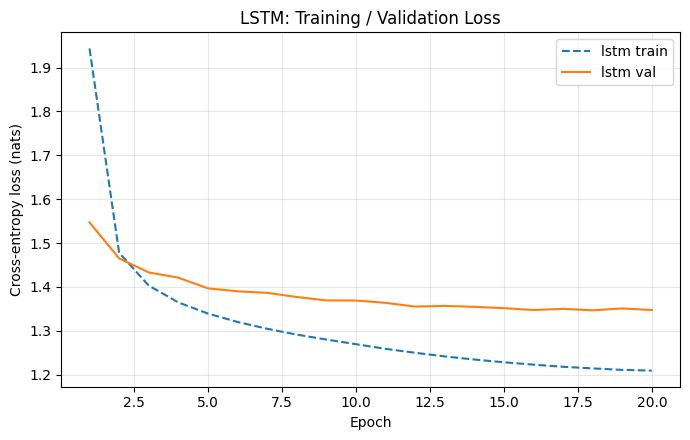

==================== epoch 1  (val loss 1.547) ====================
ROMEO:
O, thou art more look to the bed aulike o'ertilice
Have disporter of that strange majessed to hear,
With face in the scowner's lives, and robparing to the spurs'
The point points, and prayer in more common of the hate,
No longer! which see the great servants to the governous;
Thou art to prefes the 

==================== epoch 3  (val loss 1.433) ====================
ROMEO:
And then, and when I have come for me sing it.

NORTHUMBERLAND:
Now, she proud, I will have it passion of shadow,
And my majesty and dignity do whit you
think him to his whore, then, as it is dead:
Alas, I would rememper thee: and do you.

KING EDWARD IV:
You are so; for a mistress of your life see 

==================== epoch 6  (val loss 1.390) ====================
ROMEO:
A good doth like a fool?

MENAS:
What is Even hast thou done the prince?

SEBASTIAN:
The first that slew him with me as this fair voice,
I must speak me that the field you

In [24]:
# 2-1 (2) Learning curves
plot_curves([summary_lstm], "LSTM: Training / Validation Loss", os.path.join(OUT_DIR, "lstm_curves.png"))

# 2-1 (3) 5 個 breakpoint 的生成文字
for s in summary_lstm["samples"]:
    print(f"==================== epoch {s['epoch']}  (val loss {s['val_loss']:.3f}) ====================")
    print(s["text"], "\n")

In [25]:
torch.manual_seed(SEED)
gpt = MiniGPT(tok.vocab_size, BLOCK_SIZE, **GPT_CFG).to(device)
print(gpt)
print(f"參數量: {count_params(gpt):,}")

# ---- 驗證 causal mask ----
gpt.eval()
x = torch.randint(0, tok.vocab_size, (1, 32), device=device)
y = x.clone(); y[0, 20:] = torch.randint(0, tok.vocab_size, (12,), device=device)
with torch.no_grad():
    a, b = gpt(x), gpt(y)
print("causal mask 正確 (前 20 位置輸出不受未來影響):", torch.allclose(a[:, :20], b[:, :20], atol=1e-5))

MiniGPT(
  (tok_emb): Embedding(67, 256)
  (pos_emb): Embedding(128, 256)
  (drop): Dropout(p=0.2, inplace=False)
  (blocks): ModuleList(
    (0-3): 4 x Block(
      (ln1): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
      (attn): CausalSelfAttention(
        (qkv): Linear(in_features=256, out_features=768, bias=True)
        (proj): Linear(in_features=256, out_features=256, bias=True)
        (attn_drop): Dropout(p=0.2, inplace=False)
        (res_drop): Dropout(p=0.2, inplace=False)
      )
      (ln2): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
      (mlp): Sequential(
        (0): Linear(in_features=256, out_features=1024, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=1024, out_features=256, bias=True)
        (3): Dropout(p=0.2, inplace=False)
      )
    )
  )
  (ln_f): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
  (head): Linear(in_features=256, out_features=67, bias=True)
)
參數量: 3

[transformer] params=3,226,691  steps/epoch=531  breakpoints=[1, 3, 6, 12, 20]
epoch   1 | train 2.2817 | val 1.8235 | ppl 6.19 | 41.5s
epoch   2 | train 1.7721 | val 1.6487 | ppl 5.20 | 40.8s
epoch   3 | train 1.6122 | val 1.5537 | ppl 4.73 | 40.8s
epoch   4 | train 1.5259 | val 1.5205 | ppl 4.57 | 41.1s
epoch   5 | train 1.4744 | val 1.4903 | ppl 4.44 | 41.2s
epoch   6 | train 1.4392 | val 1.4739 | ppl 4.37 | 41.3s
epoch   7 | train 1.4136 | val 1.4602 | ppl 4.31 | 41.1s
epoch   8 | train 1.3929 | val 1.4433 | ppl 4.23 | 40.1s
epoch   9 | train 1.3757 | val 1.4405 | ppl 4.22 | 40.1s
epoch  10 | train 1.3609 | val 1.4223 | ppl 4.15 | 40.1s
epoch  11 | train 1.3479 | val 1.4151 | ppl 4.12 | 40.0s
epoch  12 | train 1.3363 | val 1.4139 | ppl 4.11 | 39.3s
epoch  13 | train 1.3256 | val 1.4108 | ppl 4.10 | 39.3s
epoch  14 | train 1.3162 | val 1.4068 | ppl 4.08 | 40.0s
epoch  15 | train 1.3081 | val 1.4041 | ppl 4.07 | 41.5s
epoch  16 | train 1.3010 | val 1.4015 | ppl 4.06 | 40.8s
epoch  17

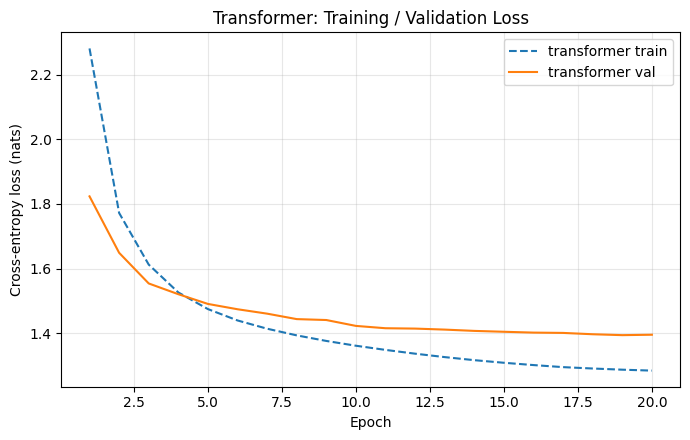

----- epoch 1 (val 1.824) -----
ROMEO:
So can meen to so server blood and to make must him:
So my away and I know and hum hymselvet the creash him his for leard?
I so mest that not to is sire havould may that commore a come, stang
Baws the love the frace the would that will commanuty's to wilt to with a stettend the must
Thee halt disio

----- epoch 3 (val 1.554) -----
ROMEO:
Then! O, thou art leave?

PANDARUS:
Nay,
A weary what I night to thee?

ROSALIND:
You go come in this, that I have sufforced and bony.

HAMLET:
And that come to the court serve and should be common the shappose of the
man of stopp: bring his eye can is of politance care,
They were proud of all the 

----- epoch 6 (val 1.474) -----
ROMEO:
I will not begin the beauty: I know you have done your state
That he now due will offend; on his short
And when you may be a most gracious straight, and there
Is the decred thrice? Thanks! my lord; the field
May be not what not had been their fortune better speech him
With my deat

In [26]:
summary_gpt = fit(gpt, train_loader, val_loader, tok, name="transformer", epochs=EPOCHS, lr=GPT_LR, prompt=PROMPT)
plot_curves([summary_gpt], "Transformer: Training / Validation Loss", os.path.join(OUT_DIR, "transformer_curves.png"))
for s in summary_gpt["samples"]:
    print(f"----- epoch {s['epoch']} (val {s['val_loss']:.3f}) -----\n{s['text']}\n")

| Model | Params | Train time / epoch (s) | Final val loss | Best val loss | Final val PPL | Final val BPC |
|---|---|---|---|---|---|---|
| lstm | 3,729,731 | 26.10 | 1.3473 | 1.3466 | 3.85 | 1.944 |
| transformer | 3,226,691 | 40.63 | 1.3949 | 1.3936 | 4.03 | 2.012 |


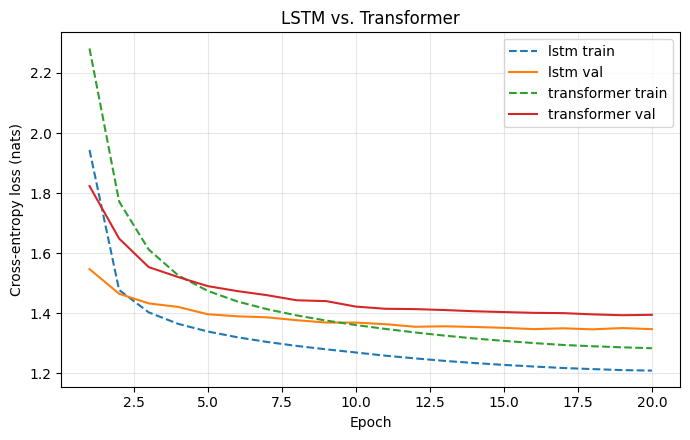

In [27]:
print("| Model | Params | Train time / epoch (s) | Final val loss | Best val loss | Final val PPL | Final val BPC |")
print("|---|---|---|---|---|---|---|")
for s in (summary_lstm, summary_gpt):
    last = s["history"][-1]
    print(f"| {s['name']} | {s['params']:,} | {s['avg_epoch_time']:.2f} | {s['final_val_loss']:.4f} | "
          f"{s['best_val_loss']:.4f} | {last['val_ppl']:.2f} | {last['val_bpc']:.3f} |")

plot_curves([summary_lstm, summary_gpt], "LSTM vs. Transformer", os.path.join(OUT_DIR, "compare_curves.png"))